In [ ]:
!pip install transformers datasets scikit-learn pandas matplotlib torch --quiet

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("/content/clickbait_data.csv")
print("Dataset shape:", df.shape)
print(df.head())

df = df.rename(columns={"headline": "headline_text", "clickbait": "label"})
df = df.dropna(subset=["headline_text", "label"])
df["label"] = df["label"].astype(int)

Dataset shape: (32000, 2)
                                            headline  clickbait
0                                 Should I Get Bings          1
1      Which TV Female Friend Group Do You Belong In          1
2  The New "Star Wars: The Force Awakens" Trailer...          1
3  This Vine Of New York On "Celebrity Big Brothe...          1
4  A Couple Did A Stunning Photo Shoot With Their...          1



Class distribution:
 label
0    16001
1    15999
Name: count, dtype: int64


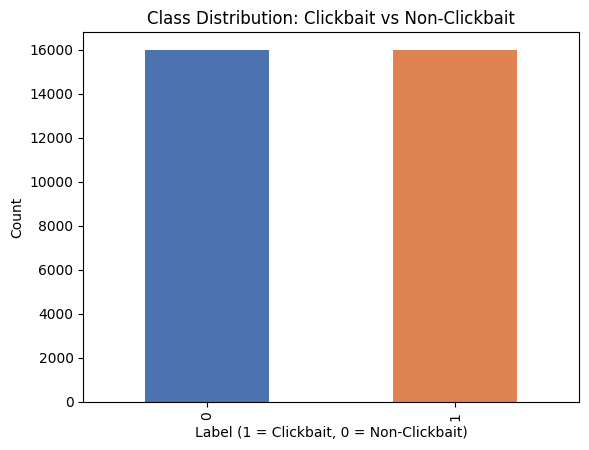


Median word count by class:
 label
0     8.0
1    10.0
Name: word_count, dtype: float64


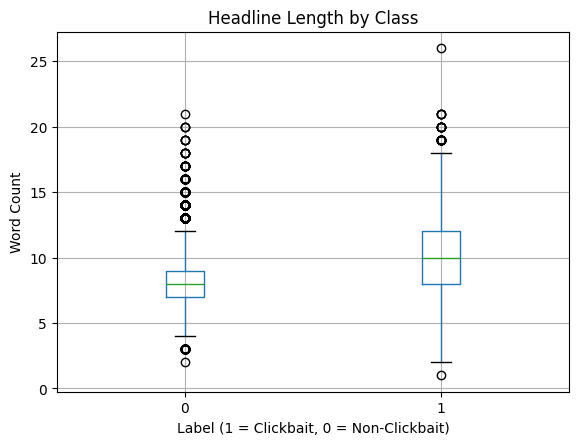

In [ ]:
import matplotlib.pyplot as plt

print("\nClass distribution:\n", df["label"].value_counts())
df["label"].value_counts().sort_index().plot(kind="bar", color=["#4c72b0", "#dd8452"])
plt.title("Class Distribution: Clickbait vs Non-Clickbait")
plt.xlabel("Label (1 = Clickbait, 0 = Non-Clickbait)")
plt.ylabel("Count")
plt.savefig("class_distribution.png")
plt.show()

df["word_count"] = df["headline_text"].apply(lambda x: len(str(x).split()))
print("\nMedian word count by class:\n", df.groupby("label")["word_count"].median())
df.boxplot(column="word_count", by="label")
plt.title("Headline Length by Class")
plt.suptitle("")
plt.xlabel("Label (1 = Clickbait, 0 = Non-Clickbait)")
plt.ylabel("Word Count")
plt.savefig("headline_length.png")
plt.show()

In [ ]:
import re

def clean_text(text):
    text = str(text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text) #
    text = re.sub(r"\s+", " ", text).strip()
    return text.lower()

df["clean_text"] = df["headline_text"].apply(clean_text)

# Remove duplicate headlines so the same headline cannot be in both train and test
before = len(df)
df = df.drop_duplicates(subset="clean_text").reset_index(drop=True)
print(f"\nRemoved {before - len(df)} duplicate headlines. Remaining: {len(df)}")


Removed 2 duplicate headlines. Remaining: 31998


In [ ]:
print(df[["headline_text", "clean_text"]].head(5).to_string())

                                                                                          headline_text                                                                                            clean_text
0                                                                                    Should I Get Bings                                                                                    should i get bings
1                                                         Which TV Female Friend Group Do You Belong In                                                         which tv female friend group do you belong in
2                             The New "Star Wars: The Force Awakens" Trailer Is Here To Give You Chills                                the new star wars the force awakens trailer is here to give you chills
3                                   This Vine Of New York On "Celebrity Big Brother" Is Fucking Perfect                                     this vine of new york on celebrity b

In [ ]:
from transformers import BertTokenizerFast #tokenizer ni

MODEL_NAME = "bert-base-uncased"
tokenizer = BertTokenizerFast.from_pretrained(MODEL_NAME)
MAX_LEN = 128

# train test split (80:20)
from sklearn.model_selection import train_test_split

train_texts, test_texts, train_labels, test_labels = train_test_split(
    df["clean_text"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print(f"\nTrain size: {len(train_texts)}  Test size: {len(test_texts)}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


Train size: 25598  Test size: 6400


In [ ]:
train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=MAX_LEN)
test_encodings = tokenizer(test_texts, truncation=True, padding=True, max_length=MAX_LEN)

In [ ]:
sample = tokenizer(train_texts[0], truncation=True, padding="max_length", max_length=20)
print("Headline:", train_texts[0])
print("Tokens:", tokenizer.convert_ids_to_tokens(sample["input_ids"]))
print("Input IDs:", sample["input_ids"])
print("Attention mask:", sample["attention_mask"])

Headline: 19 tweets about the friend zone that are way too real
Tokens: ['[CLS]', '19', 't', '##wee', '##ts', 'about', 'the', 'friend', 'zone', 'that', 'are', 'way', 'too', 'real', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
Input IDs: [101, 2539, 1056, 28394, 3215, 2055, 1996, 2767, 4224, 2008, 2024, 2126, 2205, 2613, 102, 0, 0, 0, 0, 0]
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

class ClickbaitDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = ClickbaitDataset(train_encodings, train_labels)
test_dataset = ClickbaitDataset(test_encodings, test_labels)

GPU available: True
GPU name: Tesla T4


In [ ]:
from transformers import TrainingArguments, Trainer, AutoModelForSequenceClassification
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

# Define the metric computation function
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average='binary')
    acc = accuracy_score(labels, predictions)
    return {
        'accuracy': acc,
        'f1': f1,
        'precision': precision,
        'recall': recall
    }

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="no",
    save_strategy="no",
    logging_steps=100,
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    compute_metrics=compute_metrics,
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
trainer.train()

Step,Training Loss
100,0.225601
200,0.090037
300,0.082035
400,0.085437
500,0.068553
600,0.069877
700,0.079385
800,0.063431
900,0.070456
1000,0.053594


TrainOutput(global_step=4800, training_loss=0.03323534425309238, metrics={'train_runtime': 580.121, 'train_samples_per_second': 132.376, 'train_steps_per_second': 8.274, 'total_flos': 1499615848910160.0, 'train_loss': 0.03323534425309238, 'epoch': 3.0})

Training Loss,Validation Loss,Step,Accuracy,F1,Precision,Recall
0.002196,0.081034,4800,0.986406,0.986468,0.982038,0.990938



=== Final Evaluation Results ===
{'eval_loss': 0.08103397488594055, 'eval_accuracy': 0.98640625, 'eval_f1': 0.9864675688287448, 'eval_precision': 0.9820377825952307, 'eval_recall': 0.9909375}



Confusion Matrix:
 [[3142   58]
 [  29 3171]]


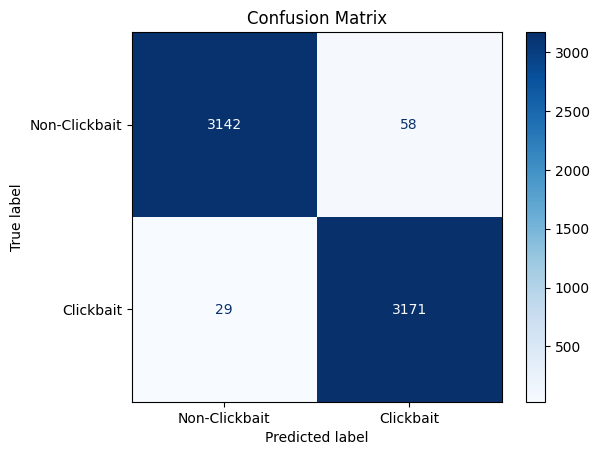


Classification Report:
                precision    recall  f1-score   support

Non-Clickbait       0.99      0.98      0.99      3200
    Clickbait       0.98      0.99      0.99      3200

     accuracy                           0.99      6400
    macro avg       0.99      0.99      0.99      6400
 weighted avg       0.99      0.99      0.99      6400



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

eval_results = trainer.evaluate(eval_dataset=test_dataset)
print("\n=== Final Evaluation Results ===")
print(eval_results)

predictions = trainer.predict(test_dataset)
preds = predictions.predictions.argmax(-1)

cm = confusion_matrix(test_labels, preds)
print("\nConfusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Clickbait", "Clickbait"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png")
plt.show()

print("\nClassification Report:\n",
      classification_report(test_labels, preds, target_names=["Non-Clickbait", "Clickbait"]))

In [ ]:
model.save_pretrained("./clickbait_bert_model")
tokenizer.save_pretrained("./clickbait_bert_model")
print("\nModel saved to ./clickbait_bert_model — ready to load into your prototype web app.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to ./clickbait_bert_model — ready to load into your prototype web app.


In [ ]:
!zip -r clickbait_bert_model.zip clickbait_bert_model

from google.colab import files
files.download("clickbait_bert_model.zip")

  adding: clickbait_bert_model/ (stored 0%)
  adding: clickbait_bert_model/tokenizer.json (deflated 71%)
  adding: clickbait_bert_model/tokenizer_config.json (deflated 43%)
  adding: clickbait_bert_model/model.safetensors (deflated 7%)
  adding: clickbait_bert_model/config.json (deflated 53%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>